# 6. Disk Winds

Besides turbulent viscosity, angular momentum in protoplanetary disks can be removed by magnetized disk winds (MHD winds). In contrast to viscosity, which redistributes angular momentum within the disk, a wind extracts angular momentum and mass from the disk surface. As a consequence, a wind-driven disk accretes without spreading and loses mass to the wind.

`TriPoDPy` can evolve the gas with a combination of turbulent viscosity and MHD disk winds following the parametrization of [Tabone et al. (2022)](https://ui.adsabs.harvard.edu/abs/2022MNRAS.512.2290T). The implementation uses the same formalism and parameter names as the disk wind module of the `DustPy` development version.

The disk wind is switched off by default.

## Theory

### Evolution equation

[Tabone et al. (2022)](https://ui.adsabs.harvard.edu/abs/2022MNRAS.512.2290T) extend the $\alpha$-viscosity framework by a second $\alpha$-parameter $\alpha_\mathrm{DW}$ that describes the vertical extraction of angular momentum by the wind and the magnetic lever arm parameter $\lambda$. The gas surface density then evolves according to

\begin{equation*}
\frac{\partial \Sigma}{\partial t} =
\underbrace{\frac{3}{r}\frac{\partial}{\partial r}\left[\frac{1}{r\Omega_\mathrm{K}}\frac{\partial}{\partial r}\left(r^2\alpha_\mathrm{SS}\Sigma c_s^2\right)\right]}_\text{viscous evolution}
+\underbrace{\frac{3}{2r}\frac{\partial}{\partial r}\left[\frac{\alpha_\mathrm{DW}\Sigma c_s^2}{\Omega_\mathrm{K}}\right]}_\text{wind-driven accretion}
-\underbrace{\frac{3\alpha_\mathrm{DW}\Sigma c_s^2}{4\left(\lambda-1\right)r^2\Omega_\mathrm{K}}}_\text{wind mass loss},
\end{equation*}

where $\alpha_\mathrm{SS}$ is the turbulent viscosity parameter (`sim.gas.alpha`), $c_s$ the isothermal sound speed and $\Omega_\mathrm{K}$ the Keplerian frequency.

The magnetic lever arm parameter $\lambda = L/\left(r^2\Omega_\mathrm{K}\right)$ is the ratio of the specific angular momentum carried away by the wind and the specific angular momentum of the disk at the launching point. It has to be larger than 1. The smaller $\lambda$, the more mass has to be ejected to extract the same amount of angular momentum.

### Wind-driven accretion velocity

The second term is an advection term with the radial velocity

\begin{equation*}
v_\mathrm{DW} = -\frac{3}{2}\frac{\alpha_\mathrm{DW}c_s^2}{r\Omega_\mathrm{K}} = -\frac{3}{2}\alpha_\mathrm{DW}\left(\frac{H}{r}\right)^2 v_\mathrm{K}.
\end{equation*}

In contrast to the viscous velocity, $v_\mathrm{DW}$ does not depend on the surface density. Mass is only transported inwards and the disk does not spread. For a passively irradiated disk with $T\propto r^{-1/2}$, $v_\mathrm{DW}$ is even independent of radius.

### Wind mass loss

The last term is a sink term that removes gas from the disk:

\begin{equation*}
\dot\Sigma_\mathrm{DW} = -\frac{3\alpha_\mathrm{DW}\Sigma c_s^2}{4\left(\lambda-1\right)r^2\Omega_\mathrm{K}} = -\frac{\Sigma\left|v_\mathrm{DW}\right|}{2\left(\lambda-1\right)r}.
\end{equation*}

The local mass loss time scale $\Sigma/|\dot\Sigma_\mathrm{DW}| = 2(\lambda-1)\,r/|v_\mathrm{DW}|$ is therefore $2(\lambda-1)$ times the local wind-driven accretion time scale.

### The $\tilde\alpha$-$\psi$ parametrization

Instead of $\alpha_\mathrm{SS}$ and $\alpha_\mathrm{DW}$ it is often convenient to use the total $\alpha$ parameter and the ratio of wind and turbulent stresses:

\begin{equation*}
\tilde\alpha = \alpha_\mathrm{SS} + \alpha_\mathrm{DW}, \qquad \psi = \frac{\alpha_\mathrm{DW}}{\alpha_\mathrm{SS}} \qquad \Leftrightarrow \qquad \alpha_\mathrm{SS} = \frac{\tilde\alpha}{1+\psi}, \qquad \alpha_\mathrm{DW} = \frac{\psi\,\tilde\alpha}{1+\psi}.
\end{equation*}

$\psi=0$ is a purely viscous disk, $\psi=\infty$ a purely wind-driven disk. Disks with the same $\tilde\alpha$ have the same accretion time scale

\begin{equation*}
t_\mathrm{acc} = \frac{r_c}{3\,\varepsilon_c\,c_{s,c}\,\tilde\alpha},
\end{equation*}

with the aspect ratio $\varepsilon = H/r$ and the sound speed at the characteristic radius $r_c$.

For constant $\alpha$ parameters and $T\propto r^{-1/2}$, Tabone et al. (2022) derived self-similar solutions of the form

\begin{equation*}
\Sigma\left(r,t\right) = \Sigma_c\left(t\right) \left(\frac{r}{r_c\left(t\right)}\right)^{-1+\xi} \exp\left(-\frac{r}{r_c\left(t\right)}\right),
\qquad
\xi = \frac{1}{4}\left(\psi+1\right)\left[\sqrt{1+\frac{4\psi}{\left(\lambda-1\right)\left(\psi+1\right)^2}}-1\right],
\end{equation*}

where the mass ejection index $\xi$ describes how much the accretion rate decreases towards the star due to the wind mass loss. For $\psi=0$ this is the Lynden-Bell & Pringle (1974) solution. For a purely wind-driven disk, $\xi = 1/\left[2\left(\lambda-1\right)\right]$, the characteristic radius stays constant and the disk mass decreases exponentially:

\begin{equation*}
M_\mathrm{D}\left(t\right) = M_\mathrm{D}\left(0\right)\,\exp\left(-\frac{t}{2\,t_\mathrm{acc}}\right).
\end{equation*}

## Implementation in TriPoDPy

* **Parameters:** The disk wind is controlled by `sim.ini.gas.alphaDiskwind` ($\alpha_\mathrm{DW}$, default: 0, i.e. no wind) and `sim.ini.gas.LambdaDiskwind` ($\lambda$, default: 3.5). The turbulent part is set as usual with `sim.ini.gas.alpha`.
* **Fields:** All disk wind quantities are stored in the group `sim.gas.diskwind`, which is updated after the pressure gradient parameter `sim.gas.eta`:
    * `alpha`: $\alpha_\mathrm{DW}$
    * `Lambda`: $\lambda$
    * `v`: wind-driven accretion velocity $v_\mathrm{DW}$
    * `S`: wind mass loss $\dot\Sigma_\mathrm{DW}$
    * `dustcoupling`: fraction of $v_\mathrm{DW}$ felt by the dust (see below)
* **Wind-driven accretion:** $v_\mathrm{DW}$ is added to the radial gas velocity `sim.gas.v.rad` and to the advection velocity of the implicit gas solver. It therefore acts on all gas components and gas tracers.
* **Wind mass loss:** $\dot\Sigma_\mathrm{DW}$ is added explicitly to the source terms of every gas component, proportional to the surface density of the component. The wind therefore removes all gas species at the same rate per unit mass, and gas tracers keep their mass fractions. The wind mass loss of every component is stored in `sim.components.<name>.gas.S.diskwind`, and the total in `sim.gas.diskwind.S`. Since the sink is explicit, it limits the time step to a fraction of the mass loss time scale. The sink is not applied in the boundary cells.
* **Dust:** The wind does not remove dust. The dust is advected with the gas velocity $v_\mathrm{g} = v_\mathrm{r} - \left(1-f_\mathrm{c}\right) v_\mathrm{DW}$, where $f_\mathrm{c}$ is `sim.gas.diskwind.dustcoupling` (default: 1). With $f_\mathrm{c}=0$ the wind-driven accretion is assumed to take place in the upper layers of the disk only and does not affect the dust in the midplane.
* **Turbulence:** The turbulent mixing of the dust (`sim.dust.delta.*`) and the TriPoD fragmentation regimes use the dust mixing parameters, which are initialized with `sim.ini.gas.alpha`, i.e. with $\alpha_\mathrm{SS}$. In purely wind-driven disks ($\alpha_\mathrm{SS}=0$) these have to be set explicitly.
* **Helper function:** `tripodpy.utils.split_alpha(alpha_tilde, psi)` returns $\alpha_\mathrm{SS}$ and $\alpha_\mathrm{DW}$ for given $\tilde\alpha$ and $\psi$.

## Setting up a wind-driven disk

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tripodpy
import dustpy.constants as c
from tripodpy.utils import split_alpha

The helper function `split_alpha` converts $\tilde\alpha$ and $\psi$ into the two $\alpha$ parameters:

In [2]:
for psi in [0., 1., 10., np.inf]:
    alpha_SS, alpha_DW = split_alpha(1.e-3, psi)
    print(f"psi = {psi:4}:  alpha_SS = {alpha_SS:.2e},  alpha_DW = {alpha_DW:.2e}")

psi =  0.0:  alpha_SS = 1.00e-03,  alpha_DW = 0.00e+00
psi =  1.0:  alpha_SS = 5.00e-04,  alpha_DW = 5.00e-04
psi = 10.0:  alpha_SS = 9.09e-05,  alpha_DW = 9.09e-04
psi =  inf:  alpha_SS = 0.00e+00,  alpha_DW = 1.00e-03


We set up a wind-dominated disk with $\tilde\alpha=10^{-3}$, $\psi=10$ and $\lambda=3$.

In [3]:
sim = tripodpy.Simulation()
sim.ini.grid.Nr = 100
sim.ini.grid.rmin = 1. * c.au
sim.ini.grid.rmax = 1000. * c.au
sim.ini.gas.alpha, sim.ini.gas.alphaDiskwind = split_alpha(1.e-3, 10.)
sim.ini.gas.LambdaDiskwind = 3.
sim.initialize()

The disk wind quantities can be found in `sim.gas.diskwind`:

In [4]:
sim.gas.diskwind

Group (Disk wind parameters)
----------------------------
    alpha        : Field (alpha disk wind parameter)
    dustcoupling : Field (Fraction of disk wind velocity felt by the dust)
    Lambda       : Field (Lambda disk wind parameter (magnetic lever arm))
    S            : Field (Disk wind source terms [g/cm²/s])
    v            : Field (Disk wind velocity contribution [cm/s])
  -----

The wind-driven accretion velocity is radially constant for the default passively irradiated disk. In the inner disk it dominates over the viscous velocity, which is ten times smaller here. In the outer disk the viscous velocity is positive (the disk spreads), while the wind always transports mass inwards.

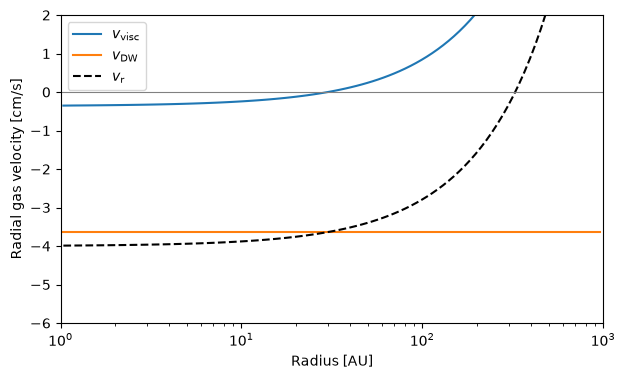

In [5]:
sim.gas.v.update()

fig, ax = plt.subplots(figsize=(7, 4))
r = sim.grid.r / c.au
ax.semilogx(r, sim.gas.v.visc, label=r"$v_\mathrm{visc}$")
ax.semilogx(r, sim.gas.diskwind.v, label=r"$v_\mathrm{DW}$")
ax.semilogx(r, sim.gas.v.rad, "k--", label=r"$v_\mathrm{r}$")
ax.axhline(0., color="gray", lw=0.8)
ax.set_xlim(1., 1000.)
ax.set_ylim(-6., 2.)
ax.set_xlabel("Radius [AU]")
ax.set_ylabel("Radial gas velocity [cm/s]")
ax.legend()
plt.show()

## Viscous vs. wind-driven evolution

To compare the evolution, we run disks with the same total $\tilde\alpha=10^{-3}$ but different $\psi$ for 1 Myr. The function below runs a model and stores a few quantities in memory. The last model is the wind-dominated disk in which the dust does not feel the wind-driven accretion.

In [6]:
def run_model(psi, dustcoupling=1., t_end=1.e6*c.year, Nsnap=25):
    sim = tripodpy.Simulation()
    sim.ini.grid.Nr = 80
    sim.ini.grid.rmin = 1. * c.au
    sim.ini.grid.rmax = 1000. * c.au
    sim.ini.gas.alpha, sim.ini.gas.alphaDiskwind = split_alpha(1.e-3, psi)
    sim.ini.gas.LambdaDiskwind = 3.
    sim.initialize()
    sim.gas.diskwind.dustcoupling[:] = dustcoupling
    sim.update()

    sim.writer = None
    sim.verbosity = 0
    res = {"t": [], "SigmaGas": [], "SigmaDust": [], "Mgas": [], "Mdust": [], "MdotWind": []}
    A = sim.grid.A
    for t in np.hstack([0., np.geomspace(1.e3*c.year, t_end, Nsnap)]):
        if t > sim.t:
            sim.t.snapshots = [t]
            sim.run()
        res["t"].append(float(sim.t))
        res["SigmaGas"].append(np.array(sim.gas.Sigma))
        res["SigmaDust"].append(np.array(sim.dust.Sigma.sum(-1)))
        res["Mgas"].append(float((sim.gas.Sigma*A).sum()))
        res["Mdust"].append(float((sim.dust.Sigma.sum(-1)*A).sum()))
        # Wind mass loss rate (the sink is not applied in the boundary cells)
        res["MdotWind"].append(float(-(sim.gas.diskwind.S*A)[1:-1].sum()))
    res = {key: np.array(val) for key, val in res.items()}
    res["r"] = np.array(sim.grid.r)
    return res

models = {
    r"viscous ($\psi=0$)": run_model(0.),
    r"hybrid ($\psi=1$)": run_model(1.),
    r"wind ($\psi=10$)": run_model(10.),
    r"wind ($\psi=10$), $f_\mathrm{c}=0$": run_model(10., dustcoupling=0.),
}

The viscous disk spreads, while the wind-driven disk keeps its outer edge and loses mass in the inner disk.

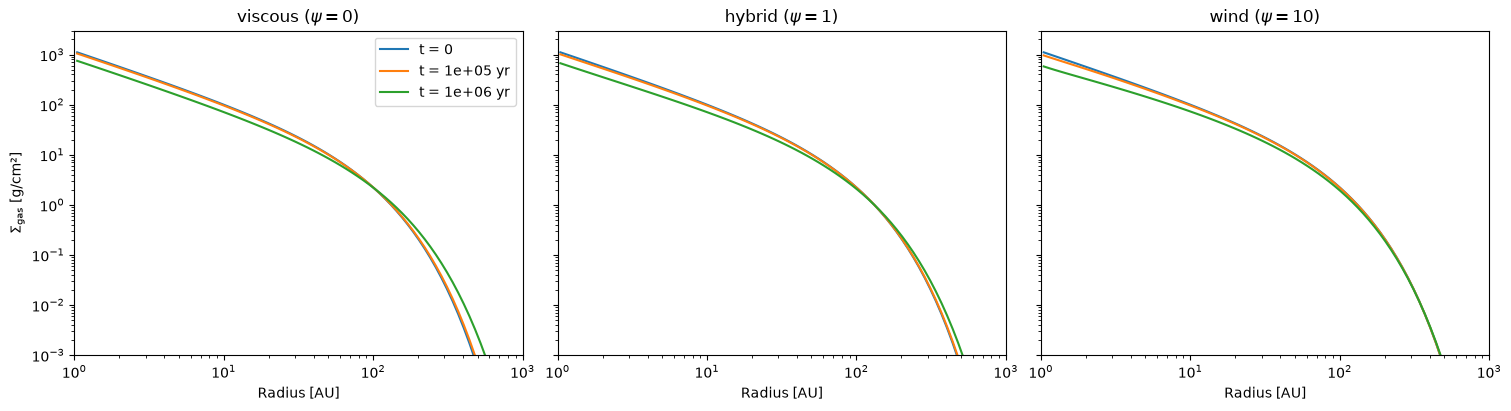

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True, constrained_layout=True)
times = np.array([0., 1.e5, 1.e6]) * c.year
for ax, (name, res) in zip(axs, list(models.items())[:3]):
    for t in times:
        i = np.argmin(np.abs(res["t"]-t))
        label = "t = 0" if t == 0. else f"t = {res['t'][i]/c.year:.0e} yr"
        ax.loglog(res["r"]/c.au, res["SigmaGas"][i], label=label)
    ax.set_title(name)
    ax.set_xlabel("Radius [AU]")
    ax.set_xlim(1., 1000.)
    ax.set_ylim(1.e-3, 3.e3)
axs[0].set_ylabel(r"$\Sigma_\mathrm{gas}$ [g/cm²]")
axs[0].legend()
plt.show()

The gas mass decreases faster the stronger the wind, because the gas is additionally removed by the wind. The dust mass is shown as well: if the dust is not coupled to the wind-driven accretion ($f_\mathrm{c}=0$), it is only transported by the remaining viscous flow and its radial drift.

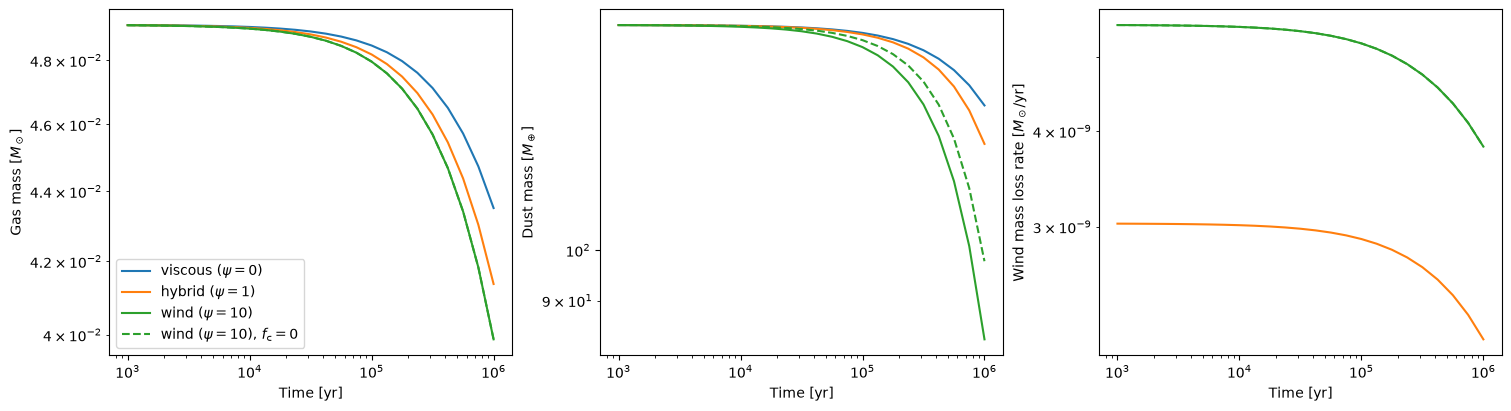

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for (name, res), col, ls in zip(models.items(), ["C0", "C1", "C2", "C2"], ["-", "-", "-", "--"]):
    t = res["t"][1:] / c.year
    axs[0].loglog(t, res["Mgas"][1:]/c.M_sun, ls, color=col, label=name)
    axs[1].loglog(t, res["Mdust"][1:]/c.M_earth, ls, color=col, label=name)
    if res["MdotWind"][0] > 0.:
        axs[2].loglog(t, res["MdotWind"][1:]/(c.M_sun/c.year), ls, color=col, label=name)
axs[0].set_ylabel(r"Gas mass [$M_\odot$]")
axs[1].set_ylabel(r"Dust mass [$M_\oplus$]")
axs[2].set_ylabel(r"Wind mass loss rate [$M_\odot$/yr]")
for ax in axs:
    ax.set_xlabel("Time [yr]")
axs[0].legend()
plt.show()

## Comparison with the analytic solution

A purely wind-driven disk ($\psi=\infty$, $\alpha_\mathrm{SS}=0$) that starts from the self-similar profile of Tabone et al. (2022) keeps its shape and loses mass exponentially on the time scale $2\,t_\mathrm{acc}$.

Since $\alpha_\mathrm{SS}=0$, the dust mixing parameters have to be set explicitly. We do this, as well as setting the initial gas surface density, after creating the grid but before initializing the simulation.

In [9]:
from simframe.frame import Field

alpha_tilde = 3.e-3
Lambda = 3.
rc = 30. * c.au
xi = 1. / (2.*(Lambda-1.))   # mass ejection index for psi = inf

sim = tripodpy.Simulation()
sim.ini.grid.Nr = 100
sim.ini.grid.rmin = 1. * c.au
sim.ini.grid.rmax = 1000. * c.au
sim.ini.gas.Mdisk = 0.01 * c.M_sun
sim.ini.gas.alpha, sim.ini.gas.alphaDiskwind = split_alpha(alpha_tilde, np.inf)
sim.ini.gas.LambdaDiskwind = Lambda
sim.makegrids()

# Dust mixing parameters (alpha_SS = 0)
Nr = int(sim.grid.Nr)
sim.dust.delta.turb = Field(sim, 1.e-3*np.ones(Nr), description="Turbulent mixing parameter")
sim.dust.delta.rad = Field(sim, 1.e-3*np.ones(Nr), description="Radial mixing parameter")
sim.dust.delta.vert = Field(sim, 1.e-3*np.ones(Nr), description="Vertical mixing parameter")

# Self-similar initial profile
def profile(r, M):
    shape = (r/rc)**(-1.+xi) * np.exp(-r/rc)
    return M * shape / (shape*sim.grid.A).sum()

sim.gas.Sigma = Field(sim, np.maximum(profile(sim.grid.r, sim.ini.gas.Mdisk), 1.e-100),
                      description="Surface density [g/cm²]")
sim.initialize()

# Accretion time scale. eps*cs = cs²/(r*OmegaK) is constant for T ∝ r^(-1/2)
eps_cs = np.interp(rc, sim.grid.r, sim.gas.cs**2/(sim.grid.r*sim.grid.OmegaK))
t_acc = rc / (3.*eps_cs*alpha_tilde)
print(f"t_acc = {t_acc/c.year:.3e} yr")

t_acc = 5.925e+05 yr


In [10]:
sim.writer = None
sim.verbosity = 0
A = sim.grid.A
M0 = float((sim.gas.Sigma*A).sum())
t, M, Sigma = [], [], []
for ti in np.linspace(0., 3.*t_acc, 13):
    if ti > sim.t:
        sim.t.snapshots = [ti]
        sim.run()
    t.append(float(sim.t))
    M.append(float((sim.gas.Sigma*A).sum()))
    Sigma.append(np.array(sim.gas.Sigma))
t, M = np.array(t), np.array(M)

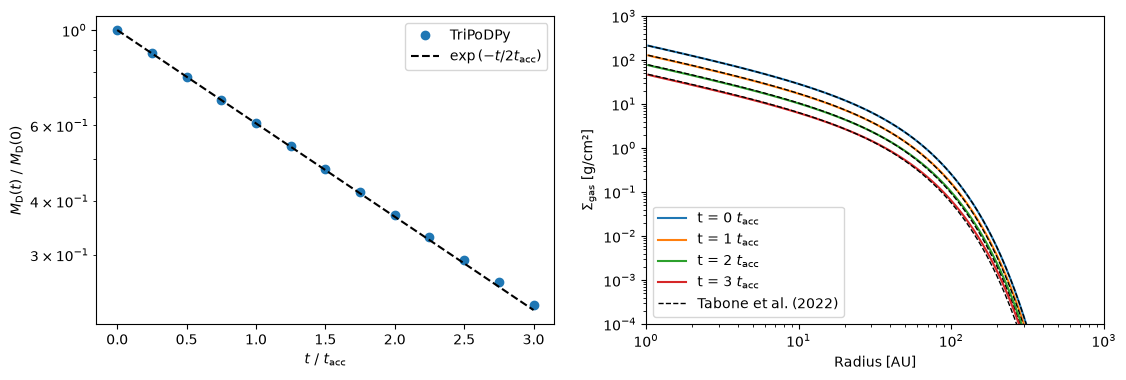

Relative deviation of the disk mass at t = 3 t_acc: +2.82%


In [11]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))

axs[0].semilogy(t/t_acc, M/M0, "o", label="TriPoDPy")
tt = np.linspace(0., t[-1], 100)
axs[0].semilogy(tt/t_acc, np.exp(-tt/(2.*t_acc)), "k--", label=r"$\exp\left(-t/2t_\mathrm{acc}\right)$")
axs[0].set_xlabel(r"$t\ /\ t_\mathrm{acc}$")
axs[0].set_ylabel(r"$M_\mathrm{D}\left(t\right)\ /\ M_\mathrm{D}\left(0\right)$")
axs[0].legend()

for i in [0, 4, 8, 12]:
    l, = axs[1].loglog(sim.grid.r/c.au, Sigma[i], label=f"t = {t[i]/t_acc:.0f} " + r"$t_\mathrm{acc}$")
    axs[1].loglog(sim.grid.r/c.au, profile(sim.grid.r, M0*np.exp(-t[i]/(2.*t_acc))), "k--", lw=1)
axs[1].plot([], [], "k--", lw=1, label="Tabone et al. (2022)")
axs[1].set_xlim(1., 1000.)
axs[1].set_ylim(1.e-4, 1.e3)
axs[1].set_xlabel("Radius [AU]")
axs[1].set_ylabel(r"$\Sigma_\mathrm{gas}$ [g/cm²]")
axs[1].legend()
plt.show()

print(f"Relative deviation of the disk mass at t = {t[-1]/t_acc:.0f} t_acc: "
      f"{M[-1]/M0/np.exp(-t[-1]/(2.*t_acc)) - 1.:+.2%}")

## Disk winds and compositional tracking

The wind removes every gas component at the same rate per unit mass, while the dust (including ices) stays in the disk. A gas tracer therefore keeps its value. To demonstrate this, we add a uniform gas tracer to a disk with a strong wind.

In [12]:
sim = tripodpy.Simulation()
sim.ini.grid.Nr = 50
sim.ini.grid.rmin = 1. * c.au
sim.ini.grid.rmax = 300. * c.au
sim.ini.gas.alpha, sim.ini.gas.alphaDiskwind = split_alpha(1.e-2, 10.)
sim.ini.gas.LambdaDiskwind = 1.5
sim.initialize()

sim.addcomponent("tracer", 0.5*np.ones(int(sim.grid.Nr)), 1., gas_tracer=True)

M0 = float((sim.gas.Sigma*sim.grid.A).sum())
sim.writer = None
sim.verbosity = 0
sim.t.snapshots = [1.e5*c.year]
sim.run()

mask = sim.gas.Sigma > 1.e-10
print(f"Remaining gas mass:  {float((sim.gas.Sigma*sim.grid.A).sum())/M0:.3f}")
print(f"Tracer value range:  {sim.components.tracer.gas.value[mask].min():.10f} - "
      f"{sim.components.tracer.gas.value[mask].max():.10f}")

Remaining gas mass:  0.673
Tracer value range:  0.5000000000 - 0.5000000000


The wind mass loss of every active gas component is stored in its source terms:

In [13]:
sim.components.Default.gas.S

Group (Gas source terms)
------------------------
    diskwind     : Field (Disk wind source term [g/cm²/s])
    ext          : Field (External source term [g/cm²/s])
    hyd          : Field (Hydrodynamical source term [g/cm²/s])
    tot          : Field (Total source term [g/cm²/s])
  -----

## Notes

* **Custom prescriptions:** $\alpha_\mathrm{DW}$ and $\lambda$ are normal fields and can be given radial profiles or updater functions, for example a time-dependent $\alpha_\mathrm{DW}$:

    ```python
    def alpha_dw(sim):
        return 1.e-3 * np.ones_like(sim.grid.r)  # replace with your prescription

    sim.gas.diskwind.alpha.updater = alpha_dw
    sim.update()
    ```

* **Time step:** The wind mass loss is integrated explicitly and limits the time step to a fraction `sim.t.cfl` of the shortest mass loss time scale $2(\lambda-1)\,r/|v_\mathrm{DW}|$. This is usually much longer than the dust time step.
* **Dust:** The wind does not remove dust or ice. Dust entrainment in the wind is not included.
* **Turbulence parameters:** The dust mixing parameters `sim.dust.delta.*` are not changed by the disk wind. They are initialized with `sim.ini.gas.alpha`, i.e. with $\alpha_\mathrm{SS}$.

### References

* Tabone, B., Rosotti, G. P., Cridland, A. J., Armitage, P. J., Lodato, G. (2022), *Secular evolution of MHD wind-driven discs: analytical solutions in the expanded α-framework*, MNRAS, 512, 2290, [doi:10.1093/mnras/stab3442](https://doi.org/10.1093/mnras/stab3442)
* Lynden-Bell, D., Pringle, J. E. (1974), *The evolution of viscous discs and the origin of the nebular variables*, MNRAS, 168, 603